# Labjournaal BM
## General

**Name:**  Sietse Venema
**Title of the experiment:**  Het Vinden van de Boltzmann Constant
**Starting date:**  9-11-2026 
**Expected enddate:**  23-11-2026        
**Partner:**  Annabel Bloem    
**Goal of the experiment:** De constant van boltzmann te vinden   
**Research question:**    Hoe nauwkeurig kan de constante van Boltzman bepaald worden door middel van een diode?     
**Expectations or Hypothesis:**  De constante van Boltzmann kan binnen een bepaalde onzekerheid gemeten worden door middel van een diode.  
**Desired accuracy:** Binnen 3% 




In [11]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  In verslag

**Theory:**  In verslag

**Independent variable:**  $U_B$

**Dependent variable:**  $I_D, U_B, U_{R1}$ 

**Controlled variablen:**  $R_1, R_2, R_3$

**Measurement instruments \& Settings:**  Twee 5 1/2 Digitale Multimeters, een spanningsverdeler, een elektronica boardje, en een stuk of 10 snoeren

**Procedure:**  In verslag

**Setup(drawing or picture):** In verslag

**Notes:**  

**About accuracy:**  



# Execution

In [13]:
# Measurements:
UB = np.array([0.1030,0.2022,0.3006,0.3997,0.5009,0.6000,0.6995,0.8030,0.9006,1.01,1.1021,1.985,2.9911,4.0030,5.0129,5.9948,1.1994,1.3005,1.4006,1.5000,1.7024,1.6004,1.8030]) #spanningmeter lezing van de bron (in volt)
UR1 = np.array([0.000012,0.000042,0.000097,0.000190,0.000347,0.0006,0.001012,0.001695,0.002721,0.004555,0.006782,0.094,0.2866,0.5063,0.7346,0.9609,0.010382,0.01552,0.022305,0.030810,0.053565,0.041247,0.067100]) #spanningmeter lezing van de resistor (in volt)
R1 = 9997.3 # Resistor 1 (in ohms)
R3 = 330.01 # Resistor 3 (in ohms)
R2 = 994.7 # Resistor 2 (in ohms)



**Observations:**  De spanningsbron was HEEL erg sensitief, zelfs een kleine beweging dat ik niet eens merkte veranderde de voltage bij 0.xx waarde. Niet fluctueren, maar echt (relatief) grote verschillen.
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


In [14]:
#Data processing and analysis:
UD = [] #Spanning over de diode
for i in range(len(UB)):
    UD = np.append(UD,(R3/(R3+R2)*UB[i]-UR1[i])) # Spanning over de spanningsverdeler - spanning over weerstand 1

ID = [] #Stroom over de diode
for i in range(len(UB)):
    ID = np.append(ID,(UR1[i]/R1)) # De setup is parallel, dus de stroom over weerstand 1 is de stroom over de diode

C:\Users\siets\AppData\Local\Temp\ipykernel_23832\2214653067.py:6: RuntimeWarning: divide by zero encountered in log
  return np.log(a *( np.e**(b*x) - 1)) #a = I0 en b = -q/(n*k_b*T), log genomen om het te linearizeren


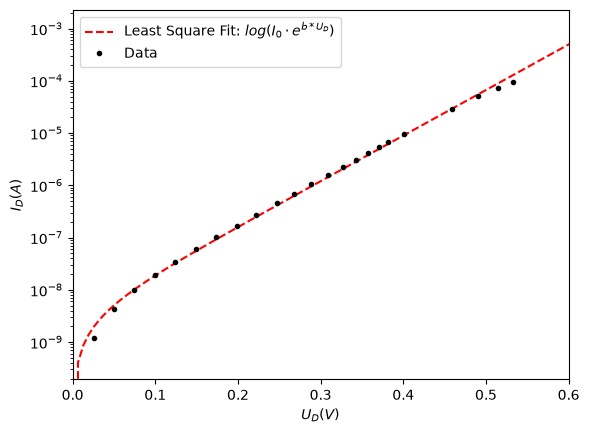

2.9066335321125694e-09
20.07909867297082


In [15]:
#Data processing and analysis:
#Plotten om b te vinden (nodig om de onzekerheid uit te rekenen):

xtest = np.linspace(0,np.max(UD)*1.2,100)
def funcfit(x,a,b):
    return np.log(a *( np.e**(b*x) - 1)) #a = I0 en b = -q/(n*k_b*T), log genomen om het te linearizeren

val, cov = curve_fit(funcfit,UD,np.log(ID),p0=(3.5e-9,19),maxfev=100000) #p0 waardes gevonden via handfitten en wat berekeningen

plt.semilogy(xtest,np.e**funcfit(xtest,*val),'r--',label = "Least Square Fit: $log(I_0 \\cdot e^{b*U_D})$",markersize=0.5) #curvefit plot, macht e gebruikt ook voor linearizate
plt.semilogy(UD,ID,'k.', label = "Data") #Data plot
plt.ylabel("$I_D (A)$")
plt.xlabel("$U_D (V)$")
plt.legend()
plt.savefig("Least_Square_Fit_BU.png", dpi = 367)
plt.xlim(0,0.6)
plt.show()
print(val[0])
print(val[1])


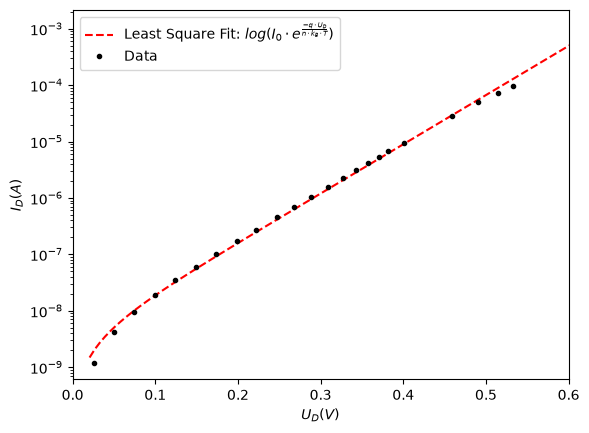

[2.90663351e-09 1.36150952e-23]


In [16]:
#Data processing and analysis:
#Plotten met daadwerkelijke functie, om onze waarde voor de Boltzmann constant te vinden:
def Echte_Functie_Fit(VD,I0,kB):
    q = -1.602*10**-19
    n = 2
    T = 293
    return np.log( I0 * (np.exp((-q*VD)/(n*kB*T)) - 1)) #Zelfde met de vorige funcfit

value, cova = curve_fit(Echte_Functie_Fit,UD,np.log(ID),p0 =(3.5e-9,1.8e-23)) #p0 waardes gevonden door handfitten en het literatuurwaarde erin te stoppen
xtest1 = np.linspace(0.8*np.min(UD),1.2*np.max(UD),100)
ytest1 = Echte_Functie_Fit(xtest1,*value)
plt.semilogy(xtest1,np.e**(ytest1),'r--',label = "Least Square Fit: $log(I_0 \\cdot e^{\\frac{-q \\cdot U_D}{n \\cdot k_B \\cdot T}})$") #curvefit plot
plt.semilogy(UD,ID,'k.', label = "Data") #Data plot
plt.xlim(0,0.6)
plt.ylabel("$I_D (A)$")
plt.xlabel("$U_D (V)$")
plt.legend()
plt.savefig("Least_Square_Fit_TF.png", dpi = 367)
plt.show()
print(value)

**Describing the pattern in the processed data:**  


In [17]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
I0, kB = value #I0 en Boltzmann volgens de optimale parameters
print(kB)
#Berekening van kB via b grootheid
b = val[1]

T = 293
q = -1.602*10**-19 #Literatuurwaarde
n = 2 #aanname
Kb = -q/(n*b*T) #Vervolg van b = -q/(n*k_B*T), en kunnen wij checken of het overeen komt met de least square fit waarde (ja)

print(Kb)

I0err, k_Berr = np.sqrt(np.diag(cova)) #k_Berr word niet gebruikt, alleen nodig zodat er geen error word gegeven

aerr, ub = np.sqrt(np.diag(cov)) #onzekerheid b

Terr = 3 #Onzekerheid T 

un = 0.1 #onzekerheid n

uKb = Kb*np.sqrt((ub/b)**2 + (un/n)**2 + (Terr/T)**2) #onzekerheid boltzmann, vervolgt van onzekerheids formule u(f)/f = sqrt((u(a)/a)^2 + (u(b)/b)^2 + . . .)

print(uKb)

1.361509516106962e-23
1.3615095181460938e-23
7.128451522017883e-25


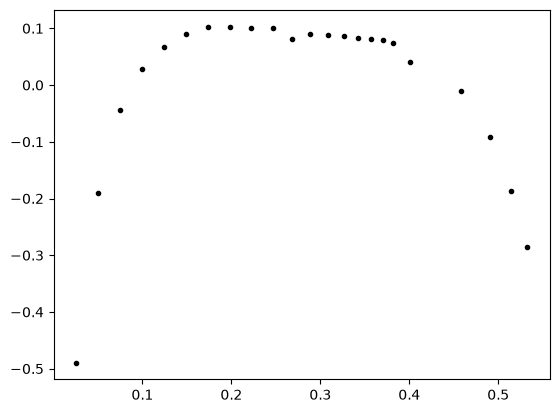

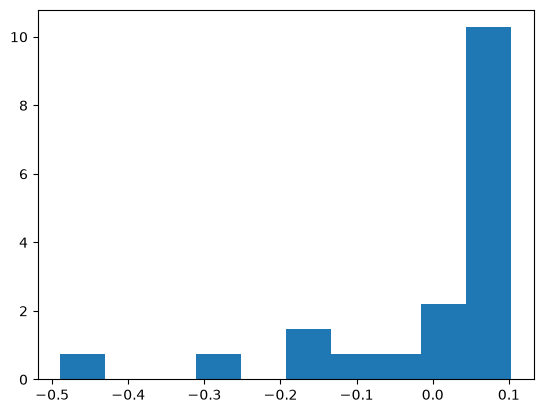

Ze zijn niet strijdig!


In [18]:
#Residuele analyse:

plt.plot(UD, np.log(ID) - Echte_Functie_Fit(UD,*value), 'k.')
plt.show()

plt.hist(np.log(ID) - Echte_Functie_Fit(UD,*value),density = True)
plt.show()

#Strijdigheids Analyse:
LkB = 1.3806503*10**-23 #Literatuurwaarde Boltzmann constant

v = np.abs(Kb - LkB) #|b-a|

u_v = np.sqrt((uKb)**2) #square root of (u(a)^2 + u(b)^2), en de literatuurwaarde heeft geen onzekerheid (SI eenheid)

if v > 2*u_v:
    print("Ze zijn strijdig...")
else:
    print("Ze zijn niet strijdig!")

**Notes:**  

# Discussion
Er is een duidelijke patroon in de residuals. Dit kan komen door meerdere dingen:
1. We hebben een aanname gedaan dat de diode ideaal was (n=2) maar dat is na hoeveel jaren gebruik zeker niet meer zo, zeker omdat de diode zelf een interne weerstand heeft (niet gemeten).

2. De spanningsbron die gebruikt is was heel erg gevoelig. Zelfs een kleine beweging dat ik niet eens kon merken veranderde de spanning bij een stap van 0.xx, dus het was moelijk om met preciese stappen de data te meten

3. Omdat de circuit warmer en warmer werd de langer dat het aan stond, kwam er thermische drift, waardoor de gemete spanning langzaam daalde. Dus er is een mogelijke verschil met de waardes na continu metingen vergeleken met als wij het koud aan zouden pakken

4. De metingen op de DMM fluctueerde veel, in de zin dat ze vaak niet een vaste waarde aanhielden. Kan komen door thermische drift, dat de spanningsbron zelf fluctueerde.


# Conclusion

In [10]:
# De gevonde waarde van Boltzmann Constant is 1.3486 * 10^-19 +/- 7.0379 * 10^-25 J/K
# Het is niet strijdig met de literatuur waarde van ~ 1.381 * 10^-19 J/k (verschil < 2σ)
# De afwijking van ongeveer 2.3% is verklaarbaar door wat genoteerd is in de discussie.

# Additional notes, remarks, explanations, thoughts etc